# Clustering & Model Evaluation

In this notebook, I will apply unsupervised machine learning algorithms to group restaurants based on their numerical features and cuisine characteristics.

I will experiment with different clustering configurations, evaluate their performance using suitable metrics, and compare the resulting clusters to identify a meaningful grouping of restaurants.

The objective is to find a clustering solution that captures similarities between restaurants while producing clusters that are interpretable and useful for further analysis.

## 1. Imports, Setup & Data Loading

I will import the necessary libraries, set up the project paths, and load the prepared feature matrix created in the previous notebook.

I will use this feature matrix as the input for clustering experiments.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Project Setup
project_root = Path.cwd().parent
processed_data_path = project_root / "1. data" / "processed" 
models_path = project_root / "4. models" 

# Loading Prepared Features
clustering_features = pd.read_csv(
    processed_data_path / "clustering_features.csv" 
)
display(clustering_features.head())
print("Feature Matrix  Shape: ", clustering_features.shape)

,Cost,avg_rating,rating_std,median_rl,avg_pic,cuisine_American,cuisine_Andhra,cuisine_Arabian,cuisine_Asian,cuisine_BBQ,...,cuisine_North Indian,cuisine_Pizza,cuisine_Salad,cuisine_Seafood,cuisine_South Indian,cuisine_Spanish,cuisine_Street Food,cuisine_Sushi,cuisine_Thai,cuisine_Wraps
0,0.142857,1.140033,-0.641610,-0.200000,-0.193182,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
1,0.142857,1.857982,-2.219528,-0.466667,-0.613636,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0.857143,1.789605,-1.859525,-0.300000,-0.011364,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
3,0.142857,-0.689027,0.585880,-0.166667,-0.295455,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,0.714286,1.242597,-1.228660,0.066667,-0.136364,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0


Feature Matrix  Shape:  (105, 49)


## 2. Determining the Optimal Number of Clusters

To determine a suitable number of clusters, I will evaluate different values of K using the Elbow Method and Silhouette Score.

The Elbow Method examines how the within-cluster sum of squared distances decreases as the number of clusters increases, while the Silhouette Score evaluates how well-separated the clusters are.

I will compare these metrics to identify a suitable number of clusters for the dataset.

In [2]:
# Evaluating Different Cluster Counts
k_values = range(2,11)
inertia_values = []
silhouette_values = []
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(clustering_features)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(clustering_features, labels))
evaluation_df = pd.DataFrame({
    "K" : list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})
display(evaluation_df)

,K,Inertia,Silhouette Score
0,2,461.720760,0.207281
1,3,406.011870,0.188467
2,4,361.736284,0.155990
3,5,334.394990,0.161117
4,6,309.018481,0.154911
5,7,294.149665,0.158625
6,8,277.364830,0.150257
7,9,269.471705,0.148933
8,10,261.136310,0.125657


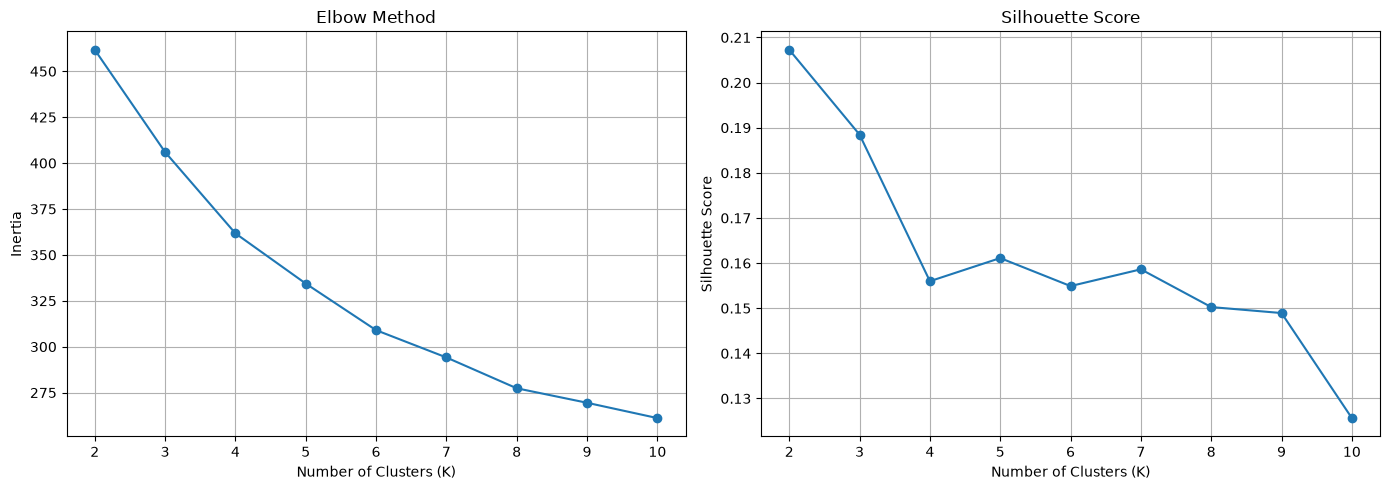

In [3]:
# Visualizing obtained evaluation metrics
fig, axes= plt.subplots(1,2,figsize=(14,5))

# Elbow Method
axes[0].plot(k_values, inertia_values, marker = "o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

# Silhouette Score
axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 2.1 Evaluation of Cluster Counts

The Elbow Method suggests that K = 4 may be a reasonable choice, as the reduction in inertia becomes more gradual beyond this point.

The Silhouette Score, however, is highest at K = 2 (0.207), indicating relatively better cluster separation at this value.

Since the two evaluation methods suggest different cluster counts, I will consider K = 2 and K = 4 as potential candidates rather than selecting a final value at this stage.

The relatively low Silhouette Scores across all tested values indicate that the clusters may not be strongly separated. I will further evaluate the clustering results before selecting the final model.

## 3. Clustering Model Comparison

I will fit K-Means models using different cluster counts and evaluate their performance using multiple clustering metrics.

Along with the evaluation scores, I will examine the distribution of restaurants across clusters to identify solutions that may produce excessively small or imbalanced groups.

In [4]:
candidate_k = [2, 3, 4] 
model_results = [] 
cluster_dist = {}
for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(clustering_features)
    model_results.append({
        "K" : k, "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(clustering_features, labels),
        "Davies Bouldin Score": davies_bouldin_score(clustering_features, labels),
        "Calinski Harabasz Score" : calinski_harabasz_score(clustering_features, labels)
    })
    cluster_dist[k] = pd.Series(labels).value_counts().sort_index()
model_comp = pd.DataFrame(model_results)
display(model_comp)

,K,Inertia,Silhouette Score,Davies Bouldin Score,Calinski Harabasz Score
0,2,461.720760,0.207281,1.701194,34.017341
1,3,406.011870,0.188467,1.716671,26.152350
2,4,361.736284,0.155990,1.730925,23.497748


In [ ]:
# Comparing Cluster Size
cluster_sizes = pd.DataFrame(cluster_dist).fillna(0).astype(int)
cluster_sizes.columns = [f"K={k}" for k in cluster_sizes.columns]
display(cluster_sizes)

,K=2,K=3,K=4
0,55,36,48
1,50,54,9
2,0,15,28
3,0,0,20


## 4. Cluster Profiling

After evaluating different cluster counts, I will examine the characteristics of the resulting restaurant groups to understand how they differ from one another.

I will assign cluster labels to the restaurants using the candidate K-Means models and compare their restaurant characteristics to identify meaningful patterns within the clusters.

In [6]:
# Fit Candidate Models and Store Cluster Labels
candidate_models = {}
candidate_labels = {}

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(clustering_features)
    candidate_models[k]= model
    candidate_labels[k] = labels
print("Candidate models and cluster labels successfully stored.")

Candidate models and cluster labels successfully stored.


In [7]:
# Load Original Restaurant Data
restaurant_data = pd.read_csv(
    processed_data_path / "restaurant_features.csv"
)

# Conversion to Numeric
restaurant_data["Cost"] = pd.to_numeric(
    restaurant_data["Cost"].astype(str).str.replace(",", "", regex=False)
)

display(restaurant_data.head())
print("Restaurant Data Shape:", restaurant_data.shape)

,Restaurant,Cost,Collections,Cuisines,avg_rating,rating_std,median_rl,avg_pic
0,Beyond Flavours,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...",4.28,1.239746,32.0,0.39
1,Paradise,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",4.70,0.771984,28.0,0.02
2,Flechazo,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts",4.66,0.878704,30.5,0.55
3,Shah Ghouse Hotel & Restaurant,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",3.21,1.603626,32.5,0.30
4,Over The Moon Brew Company,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...",4.34,1.065719,36.0,0.44


Restaurant Data Shape: (105, 8)


In [8]:
# Attaching Cluster Labels
clustered_restaurants = restaurant_data.copy()

clustered_restaurants["Cluster_K2"]= candidate_labels[2]
clustered_restaurants["Cluster_K3"] =candidate_labels[3]
clustered_restaurants["Cluster_K4"] = candidate_labels[4]

display(clustered_restaurants.head())

,Restaurant,Cost,Collections,Cuisines,avg_rating,rating_std,median_rl,avg_pic,Cluster_K2,Cluster_K3,Cluster_K4
0,Beyond Flavours,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...",4.28,1.239746,32.0,0.39,1,2,0
1,Paradise,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",4.70,0.771984,28.0,0.02,1,2,1
2,Flechazo,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts",4.66,0.878704,30.5,0.55,1,2,1
3,Shah Ghouse Hotel & Restaurant,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",3.21,1.603626,32.5,0.30,0,1,0
4,Over The Moon Brew Company,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...",4.34,1.065719,36.0,0.44,1,2,1


In [9]:
# Comparing Numeric Features across Clusters
for cluster_col in ["Cluster_K2", "Cluster_K3","Cluster_K4"]:
    numerical_profile = clustered_restaurants.groupby(cluster_col).agg(
        Cost = ("Cost","mean"), 
        avg_rating = ("avg_rating","mean"),
        rating_std = ("rating_std", "mean"),
        median_rl= ("median_rl", "mean"),
        avg_pic = ("avg_pic", "mean"),
        restaurant_count = ("Restaurant","count")
    ).round(2)
    print(f"\nNumerical Profile for {cluster_col}")
    display(numerical_profile)


Numerical Profile for Cluster_K2


,Cost,avg_rating,rating_std,median_rl,avg_pic,restaurant_count
Cluster_K2,,,,,,
0,533.64,3.33,1.53,23.7,0.32,55
1,1222.00,3.88,1.22,44.1,1.22,50



Numerical Profile for Cluster_K3


,Cost,avg_rating,rating_std,median_rl,avg_pic,restaurant_count
Cluster_K3,,,,,,
0,1112.50,3.62,1.34,46.34,1.44,36
1,528.70,3.34,1.53,23.46,0.30,54
2,1456.67,4.45,0.96,38.30,0.71,15



Numerical Profile for Cluster_K4


,Cost,avg_rating,rating_std,median_rl,avg_pic,restaurant_count
Cluster_K4,,,,,,
0,708.33,3.41,1.47,34.80,0.58,48
1,1372.22,4.59,0.81,34.72,0.44,9
2,1217.86,3.81,1.26,48.95,1.62,28
3,500.00,3.29,1.61,9.50,0.10,20


### 4.1 Numerical Cluster Profile Comparison

The numerical profiles reveal different levels of segmentation across the three candidate models.

For K = 2, the restaurants are broadly divided into lower-cost restaurants with lower ratings and less customer review engagement, and higher-cost restaurants with better ratings and greater engagement.

For K = 3, the lower-cost group remains relatively similar, while the higher-cost restaurants are further differentiated into groups with moderate and considerably higher ratings. The highest-rated group also exhibits lower rating variability.

For K = 4, the clusters become more specialized, revealing differences in rating quality, review length, and picture engagement. However, one cluster contains only 9 restaurants, which requires further examination to determine whether it represents a meaningful group.

Although K = 2 performs better according to the clustering evaluation metrics, K = 3 and K = 4 reveal additional distinctions between restaurants. I will further examine the cuisine distributions and restaurant composition of these clusters before selecting the final model.

In [10]:
# Comparing Cuisine Distribution 
for cluster_col in ["Cluster_K2","Cluster_K3","Cluster_K4"]:
    print(f"\n{'='*50}")
    print(f"Cuisine Distribution for {cluster_col}")
    print(f"{'='*50}")

    for cluster_id in sorted(clustered_restaurants[cluster_col].unique()):
        cluster_data = clustered_restaurants[
            clustered_restaurants[cluster_col] == cluster_id
        ]
        cuisine_counts = (
            cluster_data["Cuisines"]
            .dropna()
            .str.split(",")
            .explode()
            .str.strip()
        )
        cuisine_counts = cuisine_counts[cuisine_counts != ""].value_counts()
        cuisine_profile = pd.DataFrame({
            "Restaurant_Count" : cuisine_counts,
            "Percentage" : (cuisine_counts / len(cluster_data)*100).round(2)
        }).head(10)
        print(f"\nCluster {cluster_id} ({len(cluster_data)} restaurants)")
        display(cuisine_profile)
        


Cuisine Distribution for Cluster_K2

Cluster 0 (55 restaurants)


,Restaurant_Count,Percentage
Cuisines,,
North Indian,31,56.36
Chinese,25,45.45
Biryani,15,27.27
Fast Food,12,21.82
Desserts,9,16.36
South Indian,6,10.91
Andhra,5,9.09
Burger,4,7.27
Beverages,3,5.45



Cluster 1 (50 restaurants)


,Restaurant_Count,Percentage
Cuisines,,
North Indian,30,60.0
Chinese,18,36.0
Continental,18,36.0
Asian,12,24.0
Italian,12,24.0
Kebab,5,10.0
Mediterranean,5,10.0
European,4,8.0
Desserts,4,8.0



Cuisine Distribution for Cluster_K3

Cluster 0 (36 restaurants)


,Restaurant_Count,Percentage
Cuisines,,
North Indian,19,52.78
Chinese,16,44.44
Continental,12,33.33
Italian,8,22.22
Asian,5,13.89
Bakery,4,11.11
Mughlai,4,11.11
Cafe,4,11.11
Sushi,3,8.33


... (8 outputs left out)


Cluster 2 (28 restaurants)


,Restaurant_Count,Percentage
Cuisines,,
North Indian,14,50.00
Continental,13,46.43
Italian,11,39.29
Chinese,8,28.57
Asian,7,25.00
Cafe,4,14.29
Sushi,3,10.71
Desserts,3,10.71
Fast Food,3,10.71



Cluster 3 (20 restaurants)


,Restaurant_Count,Percentage
Cuisines,,
North Indian,15,75.0
Chinese,12,60.0
Biryani,6,30.0
Fast Food,4,20.0
Desserts,2,10.0
Andhra,2,10.0
Hyderabadi,2,10.0
South Indian,2,10.0
Burger,1,5.0


### 4.2 Cuisine Distribution across Clusters

The cuisine distributions reveal considerable overlap across the clusters in all three configurations. North Indian and Chinese cuisines are prevalent across most clusters, suggesting that they do not independently distinguish the restaurant groups very strongly.

In K = 2, the lower-cost cluster contains a higher proportion of Biryani and Fast Food restaurants, while the other cluster has a greater presence of Continental, Asian, and Italian cuisines.

K = 3 provides a more refined segmentation, with the higher-rated cluster containing a notable proportion of Asian, Continental, and Mediterranean restaurants. The remaining clusters retain distinct numerical profiles but share several common cuisines.

K = 4 further divides the restaurants, although the cuisine distributions continue to overlap considerably. The additional clusters appear to capture differences in numerical characteristics and customer engagement more than completely distinct cuisine categories.

Overall, cuisine composition provides useful context for interpreting the clusters, but the groups are not exclusively cuisine-based. I will further examine individual restaurants within each cluster to assess whether the resulting groups are meaningful and interpretable.

In [11]:
# Examining Representative Restaurants across Clusters
for cluster_col in ["Cluster_K2", "Cluster_K3", "Cluster_K4"]:
    print(f"\n{'='*60}")
    print(f"Restaurant Examples for {cluster_col}")
    print(f"{'='*60}")
    for cluster_id in sorted(clustered_restaurants[cluster_col].unique()):
        cluster_data = clustered_restaurants[
            clustered_restaurants[cluster_col] == cluster_id
        ].dropna(subset=["avg_rating"])
        top_restros = cluster_data.nlargest(3, "avg_rating")
        bottom_restros = cluster_data.nsmallest(3, "avg_rating")
        restaurant_ex = pd.concat(
            [top_restros, bottom_restros]
        ).drop_duplicates(subset=["Restaurant"])

        print(f"\nCluster {cluster_id}")
        display(
            restaurant_ex[
                ["Restaurant", "Cost", "avg_rating", "Cuisines"]
            ].sort_values("avg_rating",ascending=False)
        )


Restaurant Examples for Cluster_K2

Cluster 0


,Restaurant,Cost,avg_rating,Cuisines
48,Udipi's Upahar,500,4.030,"South Indian, North Indian, Chinese"
59,KS Bakers,200,3.965,"Bakery, Desserts, Fast Food"
83,GD's,500,3.960,"Burger, American"
19,Pakwaan Grand,400,2.710,"North Indian, Chinese, Biryani"
54,Asian Meal Box,200,2.580,Asian
17,Hotel Zara Hi-Fi,400,2.400,"Chinese, North Indian"



Cluster 1


,Restaurant,Cost,avg_rating,Cuisines
14,AB's - Absolute Barbecues,1500,4.880,"European, Mediterranean, North Indian"
22,B-Dubs,1600,4.810,American
27,"3B's - Buddies, Bar & Barbecue",1100,4.760,"North Indian, Mediterranean, European"
31,Pista House,1000,3.230,"Bakery, North Indian, Mughlai, Juices, Chinese"
46,Ulavacharu,1400,3.225,"Andhra, North Indian, Chinese"
44,La La Land - Bar & Kitchen,1000,3.190,"Finger Food, North Indian, Kebab, Chinese"



Restaurant Examples for Cluster_K3

Cluster 0


,Restaurant,Cost,avg_rating,Cuisines
90,Arena Eleven,1600,4.117647,Continental
16,NorFest - The Dhaba,550,4.030000,North Indian
87,American Wild Wings,600,3.974026,"American, Fast Food, Salad, Burger"
46,Ulavacharu,1400,3.225000,"Andhra, North Indian, Chinese"
44,La La Land - Bar & Kitchen,1000,3.190000,"Finger Food, North Indian, Kebab, Chinese"
47,Shanghai Chef 2,800,3.060000,"Chinese, Thai, Indonesian, Asian"


... (8 outputs left out)


Cluster 2


,Restaurant,Cost,avg_rating,Cuisines
91,Cascade - Radisson Hyderabad Hitec City,1800,4.26,"North Indian, Italian, Continental, Asian"
5,The Fisherman's Wharf,1500,4.22,"Seafood, Goan, North Indian, Continental, Asian"
56,Feast - Sheraton Hyderabad Hotel,2500,4.22,"Modern Indian, Asian, Continental, Italian"
32,Marsala Food Company,700,3.46,"Arabian, North Indian, Chinese"
13,The Lal Street - Bar Exchange,1300,3.45,"North Indian, Italian, Finger Food"
92,Collage - Hyatt Hyderabad Gachibowli,2800,3.41,"Continental, Italian, North Indian, Chinese, A..."



Cluster 3


,Restaurant,Cost,avg_rating,Cuisines
48,Udipi's Upahar,500,4.03,"South Indian, North Indian, Chinese"
23,Amul,150,3.94,"Ice Cream, Desserts"
64,Hyderabad Chefs,600,3.81,"North Indian, Chinese"
62,Shree Santosh Dhaba Family Restaurant,500,2.83,"North Indian, Chinese, Fast Food"
19,Pakwaan Grand,400,2.71,"North Indian, Chinese, Biryani"
17,Hotel Zara Hi-Fi,400,2.40,"Chinese, North Indian"


### 4.3 Restaurant Composition across Clusters

Examining individual restaurants provides additional context for interpreting the clustering results.

For K = 2, the clusters broadly distinguish lower-cost restaurants from higher-cost restaurants, although the higher-cost cluster also contains restaurants with relatively moderate ratings.

For K = 3, the lower-cost restaurant group remains recognizable, while a group of highly rated restaurants becomes more distinguishable. However, some of the remaining restaurants exhibit mixed characteristics.

K = 4 produces more specialized groups. The restaurant examples suggest a distinction between highly rated restaurants, higher-cost restaurants with substantial customer engagement, and lower-cost restaurants with varying levels of engagement. Nevertheless, some clusters still contain restaurants with diverse characteristics.

Overall, the restaurant examples provide evidence that increasing the number of clusters introduces additional distinctions, but these distinctions are not uniformly clear across all restaurants. I will consider these observations alongside the evaluation metrics and cluster profiles when selecting the final model.

## 5. Final Model Selection

After comparing K = 2, 3, and 4, I have evaluated the clustering configurations using performance metrics, cluster sizes, numerical profiles, cuisine distributions, and representative restaurants.

K = 2 performed best across the Silhouette Score, Davies-Bouldin Score, and Calinski-Harabasz Score. It also produced two reasonably balanced clusters containing 55 and 50 restaurants.

Although K = 3 and K = 4 provided more detailed groupings, their evaluation scores were comparatively weaker. The additional clusters also introduced more complexity, while some of the resulting groups continued to exhibit overlapping characteristics.

Considering the evaluation metrics, cluster balance, and interpretability, I have selected K = 2 as the final clustering configuration.

Although the Silhouette Score is relatively low, suggesting that the clusters are not strongly separated, K = 2 provides the most reasonable grouping among the configurations tested. I will use this model for the subsequent cluster analysis and visualization.

## 6. Final Clustering Results

With K = 2 selected, I will fit the final K-Means model and assign each restaurant its corresponding cluster label.

I will then validate the cluster assignments and prepare the final restaurant dataset for further analysis.

In [12]:
# Final Model
final_k = 2
final_model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)
final_labels = final_model.fit_predict(clustering_features)

# Assigning Clusters
final_restaurant_clusters = restaurant_data.copy()
final_restaurant_clusters["Clusters"] = final_labels

display(final_restaurant_clusters.head())
print("Cluster Distribution: ")
display(final_restaurant_clusters["Clusters"].value_counts().sort_index())

,Restaurant,Cost,Collections,Cuisines,avg_rating,rating_std,median_rl,avg_pic,Clusters
0,Beyond Flavours,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...",4.28,1.239746,32.0,0.39,1
1,Paradise,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",4.70,0.771984,28.0,0.02,1
2,Flechazo,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts",4.66,0.878704,30.5,0.55,1
3,Shah Ghouse Hotel & Restaurant,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",3.21,1.603626,32.5,0.30,0
4,Over The Moon Brew Company,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...",4.34,1.065719,36.0,0.44,1


Cluster Distribution: 


Clusters
0    55
1    50
Name: count, dtype: int64

In [13]:
# Validation of Results
print("Dataset Shape: ", final_restaurant_clusters.shape)
print("Number of Clusters: ", final_restaurant_clusters["Clusters"].nunique())
print("Missing Cluster Labels: ", final_restaurant_clusters["Clusters"].isna().sum())
print("Cluster Sizes: ", final_restaurant_clusters["Clusters"].value_counts().sort_index().to_dict())

Dataset Shape:  (105, 9)
Number of Clusters:  2
Missing Cluster Labels:  0
Cluster Sizes:  {0: 55, 1: 50}


## 7. Saving the Final Model and Results

I will save the final clustering model and the restaurant dataset containing the assigned cluster labels. These files will be used in the subsequent notebooks for cluster analysis, visualization, and interpretation.

In [14]:
# Saving the Clustered Dataset and Final Model
import joblib

models_path.mkdir(parents=True, exist_ok=True)
final_restaurant_clusters.to_csv(
    processed_data_path / "final_restaurant_clusters.csv",
    index=False
)
joblib.dump(
    final_model,
    models_path / "final_kmeans_model.pkl"
)

print("Final clustered dataset successfully saved.")
print("Final K-Means model saved successfully")

Final clustered dataset successfully saved.
Final K-Means model saved successfully
